In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
from pathlib import Path


output_dir = Path("images")
output_dir.mkdir(exist_ok=True)

In [ ]:
file_path = 'C:/MASTER/AC - Aprendizagem computacional/Project/DataSet/diabetes_risk.csv'

df = pd.read_csv(file_path)
df

,patient_id,age,gender,city,bmi,family_history_diabetes,physical_activity_level,diet_type,smoking_status,alcohol_consumption,hours_sleep_per_night,stress_level,fasting_blood_sugar,hba1c_level,blood_pressure_systolic,blood_pressure_diastolic,waist_circumference_cm,income_bracket,diabetes_risk
0,1,47,Female,Mumbai,26.5,Yes,Sedentary,Vegetarian,Never,Never,9.0,8,178,7.3,146,90,107.1,High,Low
1,2,53,Female,Mumbai,20.5,Yes,Moderate,Vegetarian,Never,Never,7.0,6,152,6.9,156,100,93.8,Low,Low
2,3,47,Male,Thane,31.3,No,Moderate,Non-Vegetarian,Current,Regular,7.0,7,168,6.6,150,102,113.5,Low,High
3,4,41,Male,Bengaluru,22.8,No,Sedentary,Non-Vegetarian,Never,Never,9.0,5,155,6.7,126,92,109.6,Middle,Low
4,5,57,Female,Bengaluru,16.7,No,Sedentary,Non-Vegetarian,Current,Occasional,6.5,10,188,6.7,130,90,80.8,High,Low
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14995,14996,47,Male,Mumbai,37.7,No,Sedentary,Non-Vegetarian,Never,Never,6.8,7,213,8.1,150,100,141.7,High,High
14996,14997,48,Female,Mumbai,20.6,No,Moderate,Non-Vegetarian,Never,NaN,6.0,8,162,6.5,132,80,91.0,NaN,Low
14997,14998,34,Female,Nagpur,17.9,No,Active,Vegetarian,Never,Never,7.0,6,137,6.5,136,90,88.8,Low,Low
14998,14999,56,Male,Ahmedabad,20.7,Yes,Active,Vegetarian,Never,Never,6.0,5,163,6.9,140,87,94.8,Low,Low


In [ ]:
df = df.drop(columns=['patient_id'], errors='ignore')

print("Shape:", df.shape)
df.columns

Shape: (15000, 18)


Index(['age', 'gender', 'city', 'bmi', 'family_history_diabetes',
       'physical_activity_level', 'diet_type', 'smoking_status',
       'alcohol_consumption', 'hours_sleep_per_night', 'stress_level',
       'fasting_blood_sugar', 'hba1c_level', 'blood_pressure_systolic',
       'blood_pressure_diastolic', 'waist_circumference_cm', 'income_bracket',
       'diabetes_risk'],
      dtype='object')

In [ ]:
df.describe()

,age,bmi,hours_sleep_per_night,stress_level,fasting_blood_sugar,hba1c_level,blood_pressure_systolic,blood_pressure_diastolic,waist_circumference_cm
count,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000
mean,44.333667,23.062260,7.309860,5.941200,168.789933,6.878387,139.496200,86.256933,100.207933
std,10.383753,4.046391,1.109372,2.148406,38.365822,0.843276,12.660785,8.386529,10.760331
min,18.000000,15.000000,3.000000,1.000000,72.000000,4.800000,80.000000,50.000000,73.200000
25%,38.000000,20.100000,6.700000,4.000000,145.000000,6.300000,130.000000,80.000000,92.500000
50%,45.000000,22.700000,7.000000,6.000000,165.000000,6.800000,140.000000,88.000000,99.300000
75%,52.000000,25.600000,8.000000,7.000000,189.000000,7.300000,150.000000,90.000000,106.900000
max,80.000000,40.800000,12.000000,10.000000,400.000000,13.400000,200.000000,120.000000,148.200000


In [ ]:
print("\nMissing values:")
print(df.isnull().sum())

print("\nNumber of duplicate rows:", df.duplicated().sum())



Missing values:
age                            0
gender                         0
city                           0
bmi                            0
family_history_diabetes        0
physical_activity_level        0
diet_type                      0
smoking_status               472
alcohol_consumption         3788
hours_sleep_per_night          0
stress_level                   0
fasting_blood_sugar            0
hba1c_level                    0
blood_pressure_systolic        0
blood_pressure_diastolic       0
waist_circumference_cm         0
income_bracket               463
diabetes_risk                  0
dtype: int64

Number of duplicate rows: 0


In [ ]:
print("\nUnique values in each column:")
for column in df.columns:
    print("\n", column)
    print(df[column].unique()[:20])


Unique values in each column:

 age
[47 53 41 57 58 42 44 51 38 22 26 46 49 37 40 63 45 39 55 48]

 gender
['Female' 'Male' 'Other']

 city
['Mumbai' 'Thane' 'Bengaluru' 'Hyderabad' 'Delhi' 'Kolkata' 'Ahmedabad'
 'Pune' 'Chennai' 'Kanpur' 'Bhopal' 'Visakhapatnam' 'Patna' 'Jaipur'
 'Surat' 'Nagpur' 'Indore' 'Lucknow']

 bmi
[26.5 20.5 31.3 22.8 16.7 22.  22.5 19.5 20.3 24.1 21.5 23.3 19.3 15.
 21.4 19.6 21.7 26.8 20.4 18.2]

 family_history_diabetes
['Yes' 'No']

 physical_activity_level
['Sedentary' 'Moderate' 'Active']

 diet_type
['Vegetarian' 'Non-Vegetarian' 'Pescatarian' 'Vegan']

 smoking_status
['Never' 'Current' nan 'Former']

 alcohol_consumption
['Never' 'Regular' 'Occasional' nan]

 hours_sleep_per_night
[ 9.   7.   6.5  6.9  6.   4.8  6.2 10.   8.9  8.   7.6  7.9  6.3  5.3
  8.1  6.6  7.7  8.4  8.5  7.5]

 stress_level
[ 8  6  7  5 10  2  4  9  1  3]

 fasting_blood_sugar
[178 152 168 155 188 148 190 270 186 139 158 160  94 119 118 115 167 228
 162 143]

 hba1c_level
[7.3 

diabetes_risk
Low         9000
Moderate    3750
High        2250
Name: count, dtype: int64
diabetes_risk
Low         0.60
Moderate    0.25
High        0.15
Name: proportion, dtype: float64


Text(0.5, 1.0, 'Distribution of Diabetes Risk')

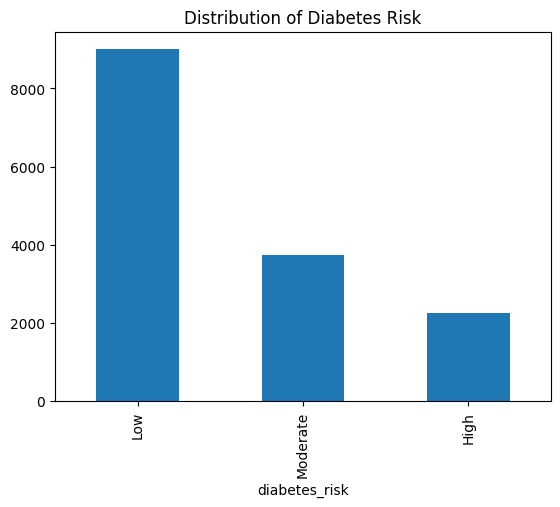

In [ ]:
print(df['diabetes_risk'].value_counts())
print(df['diabetes_risk'].value_counts(normalize=True).round(3))
df['diabetes_risk'].value_counts().plot(kind='bar')
plt.savefig(output_dir / "diabetes_risk_distribution.png", bbox_inches="tight")
plt.title('Distribution of Diabetes Risk')

In [ ]:
for c in ['smoking_status','alcohol_consumption','income_bracket']:
    df[c] = df[c].fillna('Unknown')

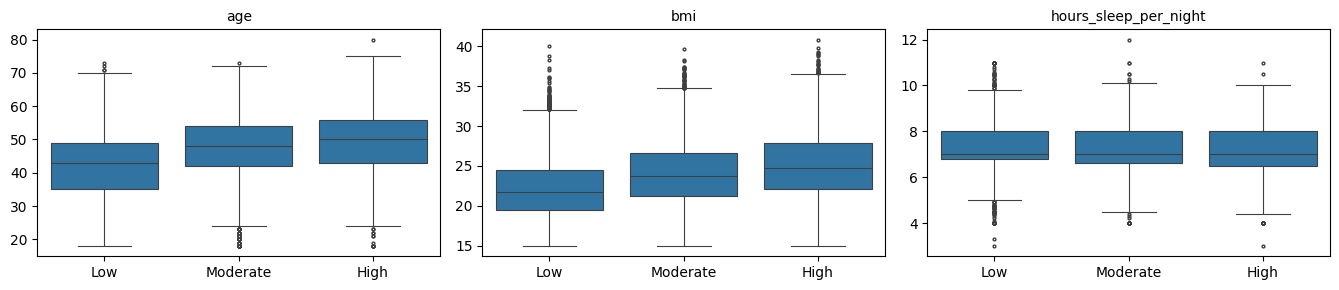

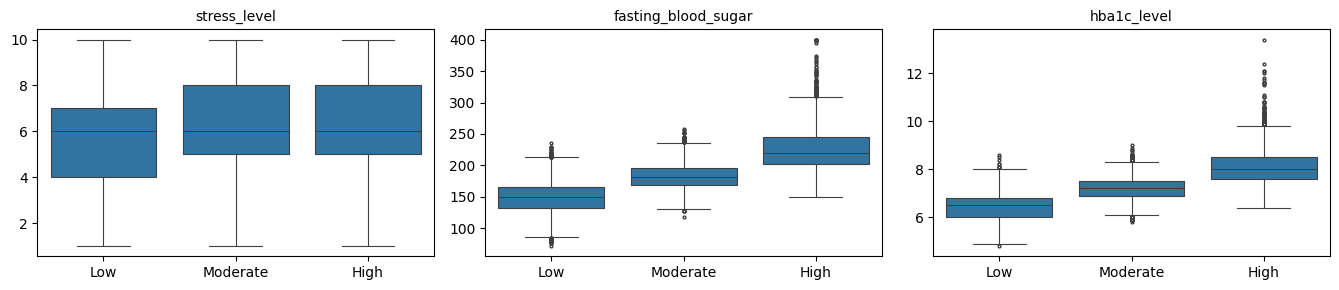

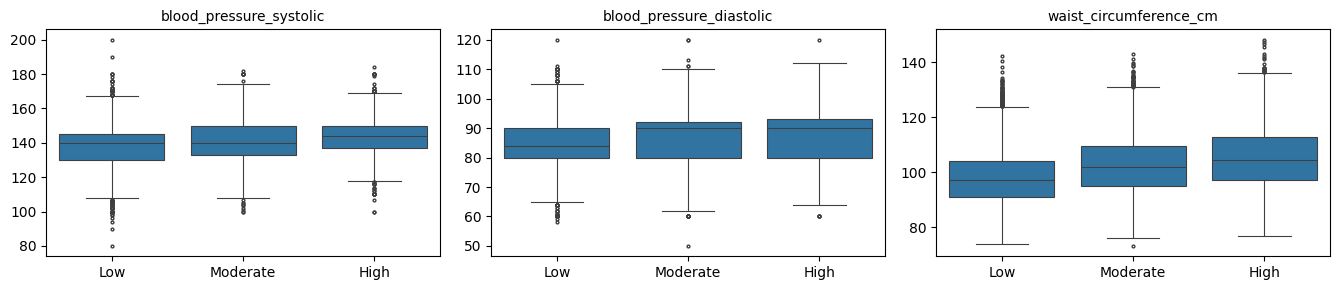

hours_sleep_per_night      -0.043301
stress_level                0.099734
blood_pressure_diastolic    0.166787
blood_pressure_systolic     0.212119
waist_circumference_cm      0.267591
age                         0.286634
bmi                         0.288707
hba1c_level                 0.733878
fasting_blood_sugar         0.738251
dtype: float64


In [ ]:
num_cols = df.select_dtypes(include=np.number).columns
order = ['Low', 'Moderate', 'High']

def boxplot_grid(cols, filename, ncols=3):
    nrows = int(np.ceil(len(cols) / ncols))
    fig, axes = plt.subplots(
        nrows, ncols, 
        figsize=(4.5*ncols, 3*nrows)
        )
    axes = np.array(axes).ravel()

    for ax, c in zip(axes, cols):
        sns.boxplot(
            data=df, 
            x='diabetes_risk',
            y=c, 
            order=order,
            ax=ax,
            fliersize=2, linewidth=0.8
        )
        ax.set_title(c, fontsize=10)
        ax.set_xlabel('')
        ax.set_ylabel('')

    for ax in axes[len(cols):]:      # esconde eixos vazios
        ax.axis('off')

    plt.tight_layout()
    plt.savefig(output_dir / filename, bbox_inches="tight")
    plt.show()


# 3 em 3 (a última grelha fica com 1 feature)
for i in range(0, len(num_cols), 3):
    boxplot_grid(list(num_cols[i:i+3]), f'boxplots_{i//3 + 1}.png')

y_ord = df['diabetes_risk'].map({'Low':0, 'Moderate':1, 'High':2})
print(df[num_cols].corrwith(y_ord).sort_values())

In [ ]:
for c in ['gender','family_history_diabetes','physical_activity_level','diet_type',
          'smoking_status','alcohol_consumption','income_bracket']:
    print(pd.crosstab(df[c], df['diabetes_risk'], normalize='index').round(3), '\n')

diabetes_risk   High    Low  Moderate
gender                               
Female         0.152  0.597     0.251
Male           0.147  0.603     0.250
Other          0.183  0.601     0.216 

diabetes_risk             High    Low  Moderate
family_history_diabetes                        
No                       0.125  0.659     0.217
Yes                      0.197  0.491     0.312 

diabetes_risk             High    Low  Moderate
physical_activity_level                        
Active                   0.098  0.701     0.201
Moderate                 0.144  0.591     0.265
Sedentary                0.210  0.505     0.285 

diabetes_risk    High    Low  Moderate
diet_type                             
Non-Vegetarian  0.149  0.601     0.250
Pescatarian     0.146  0.613     0.240
Vegan           0.192  0.559     0.248
Vegetarian      0.150  0.599     0.250 

diabetes_risk    High    Low  Moderate
smoking_status                        
Current         0.145  0.598     0.257
Former          0.1

                           age   bmi  hours_sleep_per_night  stress_level  \
age                       1.00  0.21                  -0.01          0.03   
bmi                       0.21  1.00                  -0.03          0.04   
hours_sleep_per_night    -0.01 -0.03                   1.00         -0.38   
stress_level              0.03  0.04                  -0.38          1.00   
fasting_blood_sugar       0.23  0.26                  -0.07          0.16   
hba1c_level               0.21  0.24                  -0.07          0.16   
blood_pressure_systolic   0.48  0.34                  -0.11          0.27   
blood_pressure_diastolic  0.30  0.31                  -0.10          0.27   
waist_circumference_cm    0.19  0.94                  -0.03          0.04   

                          fasting_blood_sugar  hba1c_level  \
age                                      0.23         0.21   
bmi                                      0.26         0.24   
hours_sleep_per_night                   -0.

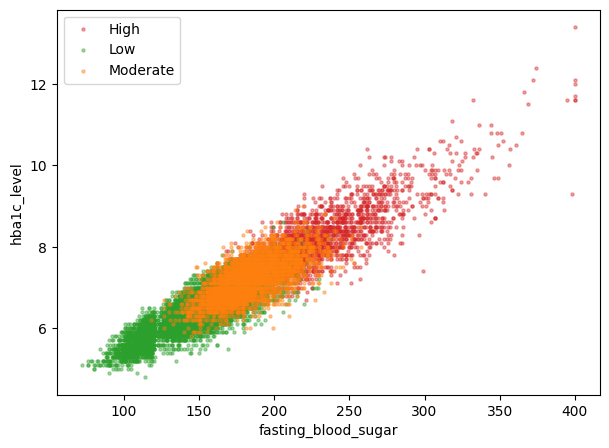

In [ ]:
num_cols = df.select_dtypes(include=np.number).columns
corr = df[num_cols].corr()
print(corr.round(2))

pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
print(pairs[abs(pairs) > 0.5].sort_values())

colors = {'Low':'tab:green','Moderate':'tab:orange','High':'tab:red'}
plt.figure(figsize=(7,5))
for k, g in df.groupby('diabetes_risk'):
    plt.scatter(g['fasting_blood_sugar'], g['hba1c_level'], s=5, alpha=0.4, c=colors[k], label=k)
plt.xlabel('fasting_blood_sugar'); plt.ylabel('hba1c_level'); plt.legend(); plt.show()


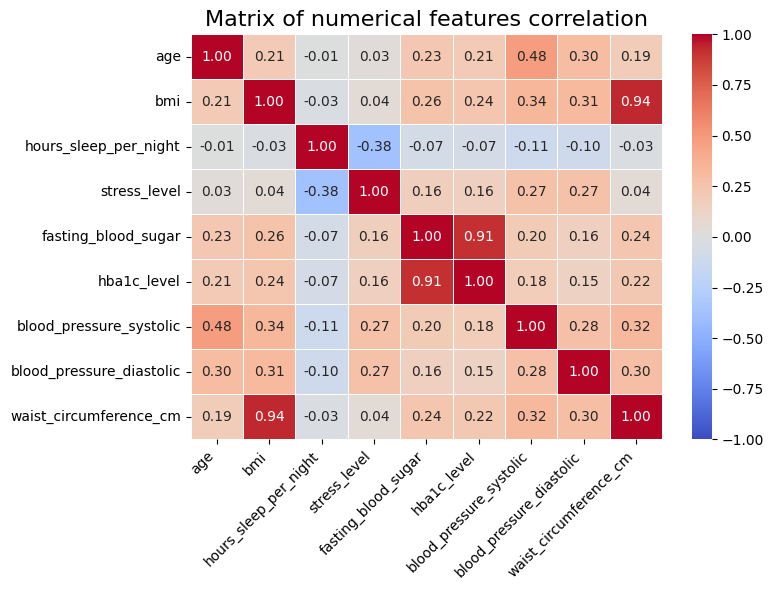

In [ ]:
plt.figure(figsize=(8,6))

sns.heatmap(
    corr,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5
)

plt.title('Matrix of numerical features correlation', fontsize=16)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig('corr_matrix.png', dpi=200, bbox_inches='tight')
plt.show()




In [ ]:
cat_cols = df.select_dtypes(exclude=np.number).columns.drop('diabetes_risk')
for c in cat_cols:
    chi2, p, dof, _ = chi2_contingency(pd.crosstab(df[c], df['diabetes_risk']))
    print(f"{c:28s} chi2={chi2:8.1f}  p={p:.4g}")

gender                       chi2=     2.7  p=0.6163
city                         chi2=    53.5  p=0.018
family_history_diabetes      chi2=   402.3  p=4.389e-88
physical_activity_level      chi2=   453.5  p=7.646e-97
diet_type                    chi2=     4.7  p=0.5826
smoking_status               chi2=     6.7  p=0.3448
alcohol_consumption          chi2=     1.7  p=0.9418
income_bracket               chi2=    25.7  p=0.0002496


In [ ]:
# Cramers V
def cramers_v(ct):
    chi2 = chi2_contingency(ct)[0]
    n = ct.values.sum()
    return np.sqrt(chi2 / (n * (min(ct.shape) - 1)))

for c in cat_cols:
    print(f"{c:28s} V={cramers_v(pd.crosstab(df[c], df['diabetes_risk'])):.3f}")

gender                       V=0.009
city                         V=0.042
family_history_diabetes      V=0.164
physical_activity_level      V=0.123
diet_type                    V=0.013
smoking_status               V=0.015
alcohol_consumption          V=0.008
income_bracket               V=0.029
